In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

from xgboost import XGBRegressor

import joblib
import os

In [2]:
train_df = pd.read_csv(
    "../data/processed/train.csv"
)

val_df = pd.read_csv(
    "../data/processed/validation.csv"
)

test_df = pd.read_csv(
    "../data/processed/test.csv"
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (1000, 10)
Validation: (600, 10)
Test: (400, 10)


In [3]:
feature_columns = [
    "sales_last_7d",
    "sales_last_30d",
    "sales_last_90d",
    "avg_daily_30d",
    "std_daily_30d",
    "month",
    "category",
    "product_id"
]

target_column = "target_next_30d"

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

In [4]:
X_train = pd.get_dummies(X_train)

X_val = pd.get_dummies(X_val)

X_test = pd.get_dummies(X_test)

# Ensure identical feature columns
X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Features:", X_train.shape[1])

Features: 111


In [5]:
baseline_val_predictions = (
    val_df["avg_daily_30d"].values * 30
)

baseline_test_predictions = (
    test_df["avg_daily_30d"].values * 30
)

In [6]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_val_predictions = rf_model.predict(X_val)

print("Random Forest training completed!")

Random Forest training completed!


In [7]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_val_predictions = xgb_model.predict(X_val)

print("XGBoost training completed!")

XGBoost training completed!


In [8]:
def evaluate_model(actual, predicted):

    mae = mean_absolute_error(
        actual, predicted
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / max(np.sum(np.abs(actual)), 1e-10)
    ) * 100

    return {
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WAPE": round(wape, 2)
    }

In [9]:
validation_results = {

    "Moving Average": evaluate_model(
        y_val, baseline_val_predictions
    ),

    "Random Forest": evaluate_model(
        y_val, rf_val_predictions
    ),

    "XGBoost": evaluate_model(
        y_val, xgb_val_predictions
    )
}

validation_results_df = pd.DataFrame(
    validation_results
).T

print(validation_results_df)

                  MAE   RMSE  WAPE
Moving Average  57.37  97.47  8.17
Random Forest   32.80  43.36  4.67
XGBoost         28.89  37.75  4.11


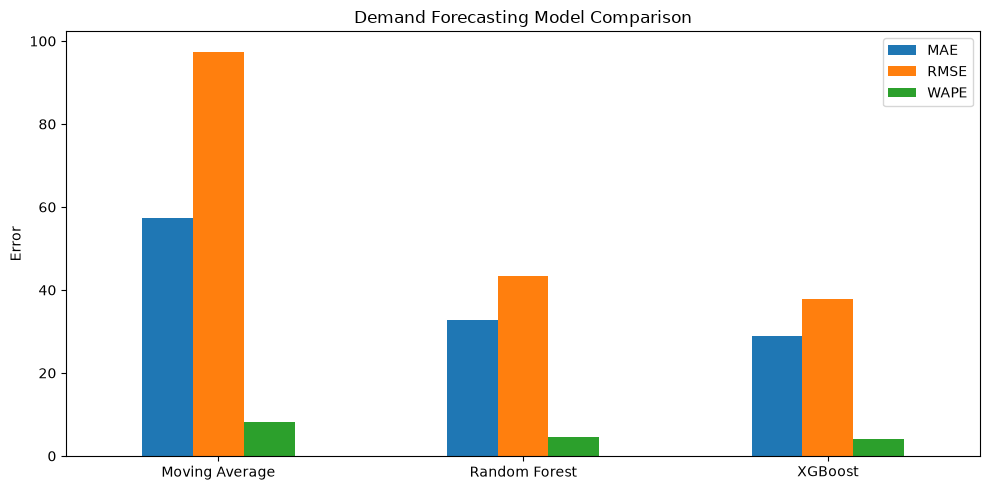

In [10]:
validation_results_df[
    ["MAE", "RMSE", "WAPE"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Demand Forecasting Model Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
best_model_name = validation_results_df[
    "WAPE"
].idxmin()

print("Best model:", best_model_name)

Best model: XGBoost


In [12]:
train_val_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

X_train_val = pd.get_dummies(
    train_val_df[feature_columns]
)

X_test_final = pd.get_dummies(
    test_df[feature_columns]
).reindex(
    columns=X_train_val.columns,
    fill_value=0
)

y_train_val = train_val_df[target_column]

In [13]:
if best_model_name == "Random Forest":

    final_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

elif best_model_name == "XGBoost":

    final_model = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

final_model.fit(X_train_val, y_train_val)

final_predictions = np.maximum(
    final_model.predict(X_test_final), 0
)

baseline_predictions = (
    test_df["avg_daily_30d"].values * 30
)

test_results = {
    "Moving Average": evaluate_model(
        y_test, baseline_predictions
    ),

    best_model_name: evaluate_model(
        y_test, final_predictions
    )
}

test_results_df = pd.DataFrame(
    test_results
).T

print(test_results_df)

                  MAE    RMSE  WAPE
Moving Average  68.34  106.95  9.93
XGBoost         28.24   37.27  4.10


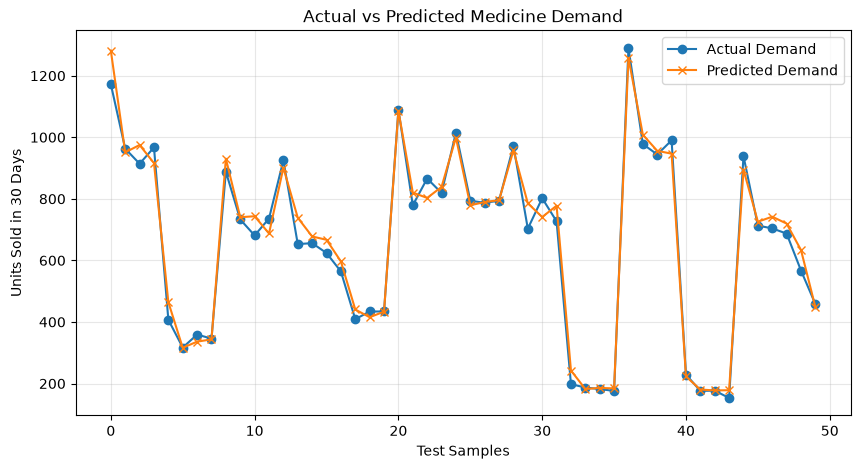

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    y_test.values[:50],
    label="Actual Demand",
    marker="o"
)

plt.plot(
    final_predictions[:50],
    label="Predicted Demand",
    marker="x"
)

plt.title("Actual vs Predicted Medicine Demand")
plt.xlabel("Test Samples")
plt.ylabel("Units Sold in 30 Days")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
os.makedirs("../models", exist_ok=True)

model_artifact = {
    "model": final_model,
    "feature_columns": list(X_train_val.columns),
    "model_name": best_model_name,
    "prediction_horizon": 30
}

joblib.dump(
    model_artifact,
    "../models/demand_model.pkl"
)

test_results_df.to_csv(
    "../reports/demand_model_metrics.csv"
)

print("Final model saved successfully!")

Final model saved successfully!


In [16]:
importance_df = pd.DataFrame({
    "Feature": X_train_val.columns,
    "Importance": final_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

              Feature  Importance
1      sales_last_30d    0.408666
3       avg_daily_30d    0.291407
2      sales_last_90d    0.130305
5               month    0.027758
95  product_id_MED085    0.006386
71  product_id_MED061    0.006079
69  product_id_MED059    0.005890
46  product_id_MED036    0.005296
22  product_id_MED012    0.004951
32  product_id_MED022    0.003585


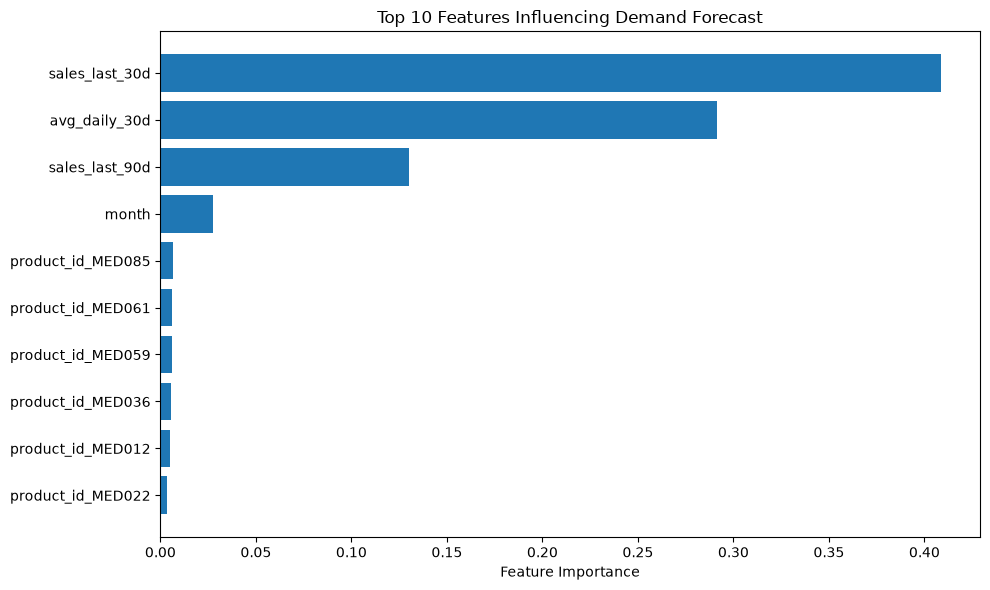

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"].head(10)[::-1],
    importance_df["Importance"].head(10)[::-1]
)

plt.title("Top 10 Features Influencing Demand Forecast")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [18]:
importance_df.to_csv(
    "../reports/feature_importance.csv",
    index=False
)

print("Feature importance saved!")


Feature importance saved!
